# Asymmetry simulation check (plan step 1)

Before changing the model code: does a non-stationary amplitude actually produce asymmetric generalization once it goes through the **real** learner model (the GP prior plus the saturating RSA speaker), and does it point the way the study 9 data do?

- **Model:** log σ(x) = log σ₀ + wᵀx / s, with s the pooled coordinate SD over all 60 set2 features, and K = diag(σ) R_ℓ diag(σ) + 10⁻⁴ I.
- **Method:** ratings-free Laplace mode (GP prior + speaker on the training generics only), the same quantity `inference.prior_pz1_modes` computes and the one the ZOIB linking is fit to. The objective is re-implemented here with the amplitude kernel; nothing in `inference.py` is modified.
- **θ:** the study 9 ZOIB posterior medians, with ℓ = 0.344, μ₀ = 1.293, σ₀ = 0.522 and β = 25.9.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import inference as inf
from model_jax import p_u_given_y, _mvn_logpdf_chol
import plot_style
plot_style.use_lexend()

LS, MU0, SIG0, BETA = 0.344, 1.293, 0.522, 25.931   # study 9 ZOIB posterior medians
CATS = ['physical', 'diet', 'personality']
CAT_COLORS = {'physical': 'tab:red', 'diet': 'tab:green', 'personality': 'tab:blue'}

geom = inf.load_geometry()
TRAIT = np.array(geom['test_trait'])
df = pd.read_pickle('../features/set2_features_dataframe.pkl')
Xf = df[['x_2d', 'y_2d']].values
S = float(np.sqrt(np.mean((Xf - Xf.mean(0)) ** 2)))   # pooled coordinate SD
cent = {c: Xf[df.category == c].mean(0) for c in ['physical', 'diet_preferences', 'personality_behaviors']}
U_AWAY = -cent['physical'] / np.linalg.norm(cent['physical'])
d = cent['diet_preferences'] - cent['personality_behaviors']
U_BOTH = np.array([d[1], -d[0]]) / np.linalg.norm(d)
U_BOTH = U_BOTH if cent['physical'] @ U_BOTH < 0 else -U_BOTH
DIRS = {'away from physical': U_AWAY, 'physical causes both': U_BOTH}
print(f's = {S:.3f}; away = {U_AWAY.round(3)}; both = {U_BOTH.round(3)}')

s = 0.197; away = [ 0.897 -0.441]; both = [ 0.701 -0.713]


In [2]:
def neg_log_post(y, ls, mu0, sig0, beta, w, X, u, s):
    # ratings-free objective (GP prior + speaker), amplitude kernel
    amp = sig0 * jnp.exp(X @ w / s)
    d2 = jnp.sum((X[:, None] - X[None]) ** 2, -1)
    K = amp[:, None] * amp[None] * jnp.exp(-d2 / (2 * ls ** 2)) + 1e-4 * jnp.eye(X.shape[0])
    J = X.shape[0] - u.shape[0]
    log_gp = _mvn_logpdf_chol(y, jnp.full(y.shape[0], mu0), K)
    log_spk = jnp.sum(jax.vmap(lambda ui, yi: jnp.log(p_u_given_y(ui, yi, beta) + 1e-300))(u, y[J:]))
    return -(log_gp + log_spk)

_vf = jax.jit(neg_log_post); _gf = jax.jit(jax.grad(neg_log_post)); _hf = jax.jit(jax.hessian(neg_log_post))

def test_mode(c, w, ls=LS, mu0=MU0, sig0=SIG0, beta=BETA):
    # damped Newton, mirroring inference.laplace_log_Z; returns y_hat at the J test features
    X = jnp.vstack([geom['x_test'], geom['x_train_cond'][c]]); u = geom['u_train_cond'][c]
    a = (ls, mu0, sig0, beta, jnp.asarray(w, float), X, u, S)
    y = jnp.full(X.shape[0], mu0); f = float(_vf(y, *a))
    for _ in range(100):
        g = _gf(y, *a)
        step = jnp.linalg.solve(_hf(y, *a) + 1e-6 * jnp.eye(len(y)), g)
        t, ok = 1.0, False
        for _ls in range(30):
            yt = y - t * step; ft = float(_vf(yt, *a))
            if np.isfinite(ft) and ft <= f - 1e-4 * t * float(g @ step):
                ok = True; break
            t *= 0.5
        if not ok:
            break
        done = float(jnp.max(jnp.abs(yt - y))) < 1e-8
        y, f = yt, ft
        if done:
            break
    return np.asarray(y[:geom['J']])

# sanity check: w = 0 must reproduce inference.prior_pz1_modes
ref = inf.prior_pz1_modes(geom, LS, MU0, SIG0, BETA)
for c in inf.CONDITIONS:
    print(f'{c:>13}: max |pz1 diff| vs inference.py = {np.abs(1 / (1 + np.exp(-test_mode(c, [0, 0]))) - ref[c]).max():.1e}')

     physical: max |pz1 diff| vs inference.py = 7.4e-10
         diet: max |pz1 diff| vs inference.py = 6.7e-10
  personality: max |pz1 diff| vs inference.py = 1.0e-09
heterogeneous: max |pz1 diff| vs inference.py = 1.3e-09


## 1. Does the asymmetry survive the speaker?

Each table is the shift of the latent coherence above the prior mean, y − μ₀, averaged over each category's 5 test features. Rows are the condition (the category of the generics heard, i.e. the source) and columns are the test category (the target).

**Asymmetry index** for a pair: shift(A → B) / shift(B → A). For example, physical → diet is (physical cond, diet column) divided by (diet cond, physical column). It's not exactly 1 at w = 0, because the clusters sit at different distances and the train blocks have different shapes.

In [3]:
def shift_table(w, **kw):
    M = np.zeros((3, 3))
    for i, c in enumerate(CATS):
        y = test_mode(c, w, **kw)
        M[i] = [(y[TRAIT == t] - kw.get('mu0', MU0)).mean() for t in CATS]
    return M

def asym(M):
    return {f'{CATS[a]}→{CATS[b]}': M[a, b] / M[b, a] for a, b in [(0, 1), (0, 2), (1, 2)]}

rows = []
tables = {('w = 0', 0): shift_table([0, 0])}
for dname, u in DIRS.items():
    for m in [0.25, 0.5, 1.0]:
        tables[(dname, m)] = shift_table(m * u)
for (dname, m), M in tables.items():
    rows.append({'direction': dname, '|w|': m, **{k: round(v, 2) for k, v in asym(M).items()},
                 'physical own shift': round(M[0, 0], 3)})
summary = pd.DataFrame(rows)
summary

,direction,|w|,physical→diet,physical→personality,diet→personality,physical own shift
0,w = 0,0.00,0.77,1.10,1.47,0.366
1,away from physical,0.25,1.25,1.52,1.21,0.250
2,away from physical,0.50,1.96,1.96,0.95,0.160
3,away from physical,1.00,4.57,3.09,0.52,0.066
4,physical causes both,0.25,1.10,1.66,1.52,0.253
5,physical causes both,0.50,1.51,2.41,1.57,0.164
6,physical causes both,1.00,2.78,5.02,1.57,0.070


In [4]:
for key in [('w = 0', 0), ('away from physical', 0.5), ('physical causes both', 0.5)]:
    print(f'--- {key[0]}' + ('' if key[1] == 0 else f', |w| = {key[1]}') + ' ---   shift of y above mu_0')
    print(pd.DataFrame(tables[key], index=[f'{c} cond' for c in CATS], columns=CATS).round(3).to_string(), '\n')

--- w = 0 ---   shift of y above mu_0
                  physical   diet  personality
physical cond        0.366  0.128        0.238
diet cond            0.166  0.384        0.213
personality cond     0.216  0.145        0.391 

--- away from physical, |w| = 0.5 ---   shift of y above mu_0
                  physical   diet  personality
physical cond        0.160  0.181        0.242
diet cond            0.093  0.546        0.221
personality cond     0.123  0.233        0.465 

--- physical causes both, |w| = 0.5 ---   shift of y above mu_0
                  physical   diet  personality
physical cond        0.164  0.144        0.289
diet cond            0.096  0.456        0.275
personality cond     0.120  0.176        0.514 



**What this shows:**
- The asymmetry **survives** the saturating speaker and goes in the predicted direction. Physical → diet/personality grows relative to the reverse as |w| increases.
- It's **much weaker than the raw σ-ratio theory**. At |w| = 0.5 away from physical, the noise-free factor (σ_t/σ_s)² is about 10× for physical ↔ diet, but the simulated index only moves from about 0.8 to about 2.
  - **Why (exact):** at the Laplace mode, y − μ₀ = K·α, where α = ∂ log p(u | y)/∂y is the speaker's slope at each train feature (nonzero only at train features). So a test feature's shift is Σₛ K_ts αₛ = σ_t Σₛ σₛ ρ_ts αₛ. That's the **symmetric** kernel times the speaker slopes.
  - For a single source and target, the asymmetry index is therefore exactly α_A / α_B: σ_A and σ_B cancel. Amplitude creates asymmetry only *indirectly*, through saturation. A low-σ source stays near μ₀, where the speaker's slope is steep, so α is large. A high-σ source climbs to where the speaker saturates, so α is small.
  - The qmd's (σ_t/σ_s)² factor assumes the source value is *observed exactly*. A generic is a soft likelihood, so the source's own posterior value shrinks with σ_s, roughly σ_s^1.6 here. In the physical condition, the train-feature shift goes 0.37 → 0.065 as their mean σ goes 0.52 → 0.17.
- **The tension is real.** The physical condition's own boost is about σ_phys² ρ α_phys, since the physical test and train features sit in the same low-σ region. So lowering σ_phys to make physical a strong source also shrinks its own boost: the physical own shift goes 0.37 → 0.16 → 0.07 as |w| goes 0 → 0.5 → 1.

## 2. What the study 9 data look like

Mean slider rating (0–1) for each condition × test category. The second table subtracts the heterogeneous condition, as a rough baseline.

In [5]:
R, _ = inf.load_responses('../../data/study9_prereg.csv', clip_interior=False)
emp = pd.DataFrame([[np.asarray(R[c])[:, TRAIT == t].mean() for t in CATS] for c in inf.CONDITIONS],
                   index=[f'{c} cond' for c in inf.CONDITIONS], columns=CATS)
emp_shift = emp.iloc[:3] - emp.iloc[3].values
print(emp.round(3).to_string(), '\n\nminus heterogeneous:\n', emp_shift.round(3).to_string())
print('\nempirical asymmetry index (on the minus-heterogeneous shifts):',
      {k: round(v, 1) for k, v in asym(emp_shift.values).items()})

                    physical   diet  personality
physical cond          0.585  0.576        0.634
diet cond              0.464  0.553        0.594
personality cond       0.464  0.492        0.643
heterogeneous cond     0.458  0.478        0.567 

minus heterogeneous:
                   physical   diet  personality
physical cond        0.127  0.098        0.066
diet cond            0.006  0.076        0.027
personality cond     0.006  0.014        0.076

empirical asymmetry index (on the minus-heterogeneous shifts): {'physical→diet': np.float64(15.2), 'physical→personality': np.float64(11.5), 'diet→personality': np.float64(1.9)}


**What this shows:** the data have a strong **physical-as-source** asymmetry. Physical generics lift diet and personality features a lot, while diet or personality generics barely move physical features. **At the same time**, physical's own boost is the largest in the table. Under the amplitude model these two pull against each other: under saturation, both "physical receives little" and "physical's own boost" are governed by σ at physical.

These are raw ratings, though, and the per-feature linking function sits between them and the latent coherence. So compare patterns, not magnitudes.

## 3. The two signatures across w

The data show two signatures:
- **A, physical as a source:** the geometric mean of the asymmetry indices physical → diet and physical → personality. In the data, A ≈ 13.
- **B, physical's own boost:** the physical condition's own shift divided by the mean of the diet and personality own shifts. In the data, B ≈ 1.7.

Both are ratios, so they can be compared roughly across units (latent y for the model, ratings minus heterogeneous for the data). Each heatmap below maps one signature over a grid of w, with ℓ, μ₀, σ₀ and β held at the stationary fit. If some region of w matched both, the amplitude model could plausibly fit the pattern. This is only a fixed-θ diagnostic; the VBMC fit in plan step 4 can also adjust ℓ, μ₀, σ₀ and β.

In [6]:
def signatures(M):
    a = asym(M)
    A = np.sqrt(max(a['physical→diet'], 1e-9) * max(a['physical→personality'], 1e-9))
    B = M[0, 0] / np.mean([M[1, 1], M[2, 2]])
    return A, B

A_emp, B_emp = signatures(emp_shift.values)
grid = np.linspace(-1.5, 1.5, 13)
A = np.zeros((len(grid), len(grid))); B = np.zeros_like(A)
for i, w2 in enumerate(grid):
    for j, w1 in enumerate(grid):
        A[i, j], B[i, j] = signatures(shift_table([w1, w2]))
print(f'data: A = {A_emp:.1f}, B = {B_emp:.2f};   model at w = 0: A = {A[6, 6]:.2f}, B = {B[6, 6]:.2f}')
print(f'model max A over grid = {A.max():.1f};  B where A >= 3: max {B[A >= 3].max() if (A >= 3).any() else np.nan:.2f}')

data: A = 13.2, B = 1.67;   model at w = 0: A = 0.92, B = 0.95
model max A over grid = 17.1;  B where A >= 3: max 0.90


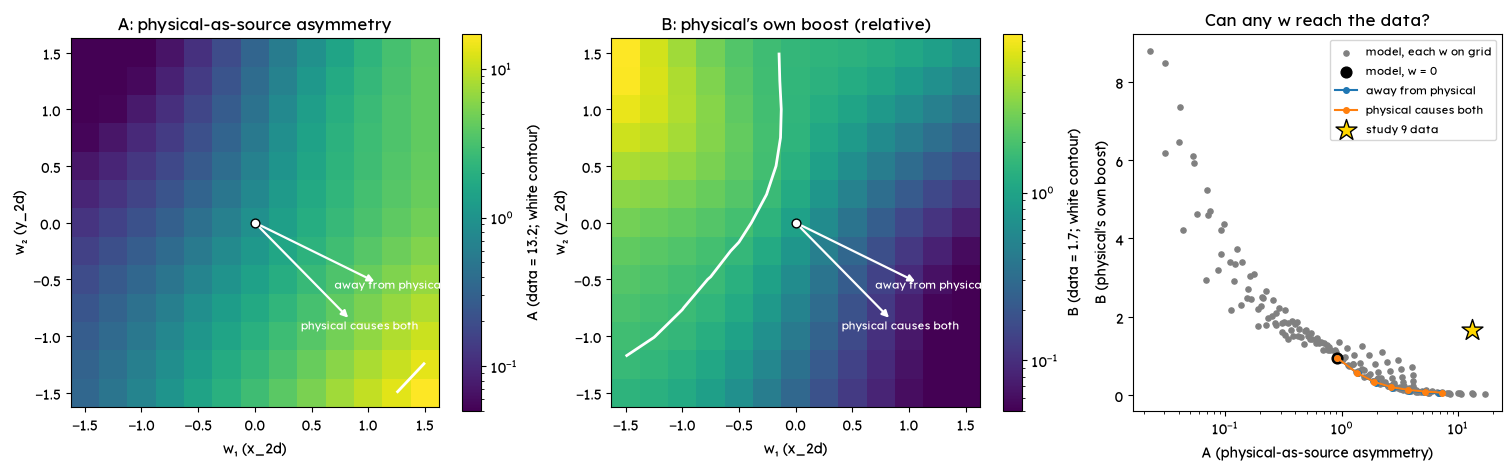

In [7]:
from matplotlib.colors import LogNorm
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, Z, name, target in [(axes[0], A, 'A: physical-as-source asymmetry', A_emp),
                            (axes[1], B, "B: physical's own boost (relative)", B_emp)]:
    im = ax.pcolormesh(grid, grid, Z, cmap='viridis', shading='auto',
                       norm=LogNorm(vmin=max(Z.min(), 0.05), vmax=max(Z.max(), target)))
    ax.contour(grid, grid, Z, levels=[target], colors='white', linewidths=2)
    fig.colorbar(im, ax=ax, label=f'{name.split(":")[0]} (data = {target:.1f}; white contour)')
    ax.set_title(name)
for ax in axes[:2]:
    for dname, u in DIRS.items():
        ax.annotate('', xy=1.2 * u, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='white', lw=1.6))
        ax.text(*(1.32 * u), dname, color='white', fontsize=8, ha='center')
    ax.scatter(0, 0, c='white', edgecolors='k', s=40, zorder=3)
    ax.set_xlabel('w₁ (x_2d)'); ax.set_ylabel('w₂ (y_2d)'); ax.set_aspect('equal')
ax = axes[2]
ax.scatter(A.ravel(), B.ravel(), c='grey', s=14, label='model, each w on grid')
ax.scatter([A[6, 6]], [B[6, 6]], c='k', s=60, label='model, w = 0')
for dname, u in DIRS.items():
    pts = np.array([signatures(shift_table(m * u)) for m in np.linspace(0, 1.5, 7)])
    ax.plot(pts[:, 0], pts[:, 1], '-o', ms=4, label=dname)
ax.scatter([A_emp], [B_emp], marker='*', s=250, c='gold', edgecolors='k', zorder=4, label='study 9 data')
ax.set_xscale('log'); ax.set_xlabel('A (physical-as-source asymmetry)'); ax.set_ylabel("B (physical's own boost)")
ax.set_title('Can any w reach the data?'); ax.legend(fontsize=8)
plt.show()

## 4. A check the linking function can't distort: ratios within a feature

A and B compare shifts at **different** features, so per-feature linking slopes could distort them. A cleaner check compares conditions **within** one test category. Each test feature has a single linking function, so a ratio of its own shifts across conditions is roughly linking-invariant:
- **physical features:** shift in the physical condition ÷ the mean shift in the diet and personality conditions;
- **diet features:** shift in the physical condition ÷ shift in the diet condition;
- **personality features:** shift in the physical condition ÷ shift in the personality condition.

Under saturation, the amplitude at a target multiplies **all** of that feature's shifts, so these ratios should barely depend on w.

In [8]:
def within(M):
    return {'physical feats: own / others': M[0, 0] / np.mean([M[1, 0], M[2, 0]]),
            'diet feats: from physical / own': M[0, 1] / M[1, 1],
            'personality feats: from physical / own': M[0, 2] / M[2, 2]}

rows = [{'source': 'study 9 data', **within(emp_shift.values)}]
for (dname, m), M in tables.items():
    rows.append({'source': dname + ('' if m == 0 else f', |w|={m}'), **within(M)})
pd.DataFrame(rows).set_index('source').round(2)

,physical feats: own / others,diet feats: from physical / own,personality feats: from physical / own
source,,,
study 9 data,20.75,1.30,0.87
w = 0,1.92,0.33,0.61
"away from physical, |w|=0.25",1.73,0.33,0.57
"away from physical, |w|=0.5",1.48,0.33,0.52
"away from physical, |w|=1.0",1.06,0.36,0.43
"physical causes both, |w|=0.25",1.75,0.33,0.59
"physical causes both, |w|=0.5",1.52,0.32,0.56
"physical causes both, |w|=1.0",1.15,0.31,0.58


**What this shows:** along these two hypothesis directions, the within-feature ratios change little with w. (Section 5 shows that other directions move them more, but still not to the data.) The diet and personality ratios are nearly constant. The physical ratio moves *away* from the data as |w| grows: about 1.9 at w = 0, about 1.1 at |w| = 1. They are also far from the data in every case:
- **Physical features respond almost only to physical generics.** In the data, the ratio of own to others is around 20; in the model it's about 2 or less.
- **Diet and personality features respond as much or more to physical generics as to their own category's generics.** In the data that ratio is about 0.9–1.3; in the model it's about 0.3–0.6.

So the main study 9 pattern is that **physical generics spread broadly and other generics spread narrowly**, and it doesn't come from per-feature amplitude. An amplitude mostly rescales each target feature's overall responsiveness, which the per-feature linking can already absorb. The pattern looks instead like a property of the **source**: physical generics carry more evidence, or are read as more kind-linked, and so spread further.

## 5. Proxy: could a re-fit with a lower μ₀ rescue the amplitude model?

Sections 1–4 held μ₀ at 1.293. In a real fit with w free, μ₀ (and σ₀) could move. A lower μ₀ puts the train features further below the generic's "target" at y ≈ 2, which changes the speaker slopes α.

This section repeats the check over a grid of **μ₀ ∈ {−1, 0, 0.75, 1.293, 2}** × **σ₀ ∈ {0.522, 1.0}** × a 7×7 grid of w (−1.5 to 1.5 on each axis), with ℓ and β kept at the fit. For each setting it computes the signatures A and B and the three within-feature ratios from section 4. If some combination comes near the data, the full VBMC fit (plan step 2) is worth doing. If none does, it probably isn't.

This is still a proxy: there's no likelihood and no linking function, and it only shows whether the *pattern* is reachable.

In [9]:
MU0_GRID = [-1.0, 0.0, 0.75, MU0, 2.0]
SIG0_GRID = [SIG0, 1.0]
WG = np.linspace(-1.5, 1.5, 7)

recs = []
for mu0 in MU0_GRID:
    for sig0 in SIG0_GRID:
        for w1 in WG:
            for w2 in WG:
                M = shift_table([w1, w2], mu0=mu0, sig0=sig0)
                A_, B_ = signatures(M)
                recs.append({'mu0': mu0, 'sig0': sig0, 'w1': w1, 'w2': w2, 'A': A_, 'B': B_, **within(M)})
proxy = pd.DataFrame(recs)
emp_within = within(emp_shift.values)
print('data:', {'A': round(A_emp, 1), 'B': round(B_emp, 2), **{k: round(v, 2) for k, v in emp_within.items()}})
print(proxy.groupby(['mu0', 'sig0'])[['A', 'B'] + list(emp_within)].agg(['min', 'max']).round(2).to_string())

data: {'A': np.float64(13.2), 'B': np.float64(1.67), 'physical feats: own / others': np.float64(20.75), 'diet feats: from physical / own': np.float64(1.3), 'personality feats: from physical / own': np.float64(0.87)}
                 A            B        physical feats: own / others       diet feats: from physical / own       personality feats: from physical / own      
               min    max   min    max                          min   max                             min   max                                    min   max
mu0    sig0                                                                                                                                                 
-1.000 0.522  0.03  15.02  0.02  15.48                         0.58  5.43                            0.26  2.19                                   0.28  1.52
       1.000  0.02  35.19  0.06   6.17                         0.31  3.02                            0.24  3.75                                   0.48  2.05

In [10]:
# distance to the data on the linking-robust within-feature ratios (log scale; all ratios must be > 0)
keys = list(emp_within)
L = np.log(np.clip(proxy[keys].values, 1e-3, None)) - np.log(np.array([emp_within[k] for k in keys]))
proxy['dist_within'] = np.sqrt((L ** 2).mean(1))
L2 = np.log(np.clip(proxy[['A', 'B']].values, 1e-3, None)) - np.log([A_emp, B_emp])
proxy['dist_AB'] = np.sqrt((L2 ** 2).mean(1))
ref = proxy[(proxy.mu0 == MU0) & (proxy.sig0 == SIG0) & (proxy.w1 == 0) & (proxy.w2 == 0)].iloc[0]
print(f"current fit (w = 0): dist_within = {ref.dist_within:.2f}, dist_AB = {ref.dist_AB:.2f}   (0 = matches data; 1 ≈ off by a factor of e)")
print('\nbest 8 settings by within-feature distance:')
print(proxy.sort_values('dist_within').head(8).round(2).to_string(index=False))

current fit (w = 0): dist_within = 1.60, dist_AB = 1.93   (0 = matches data; 1 ≈ off by a factor of e)

best 8 settings by within-feature distance:
  mu0  sig0   w1   w2    A    B  physical feats: own / others  diet feats: from physical / own  personality feats: from physical / own  dist_within  dist_AB
-1.00  0.52  1.5  1.5 7.14 0.37                          5.43                             2.19                                    1.31         0.86     1.15
-1.00  0.52  1.0  1.5 2.61 0.52                          4.57                             0.97                                    1.52         0.95     1.41
 0.00  0.52  1.0  1.5 2.24 1.02                          3.98                             1.92                                    1.48         1.03     1.30
 0.75  0.52  1.0  1.5 2.25 1.06                          4.01                             1.97                                    1.48         1.03     1.29
 1.29  0.52  1.0  1.5 2.21 1.10                          3.94      

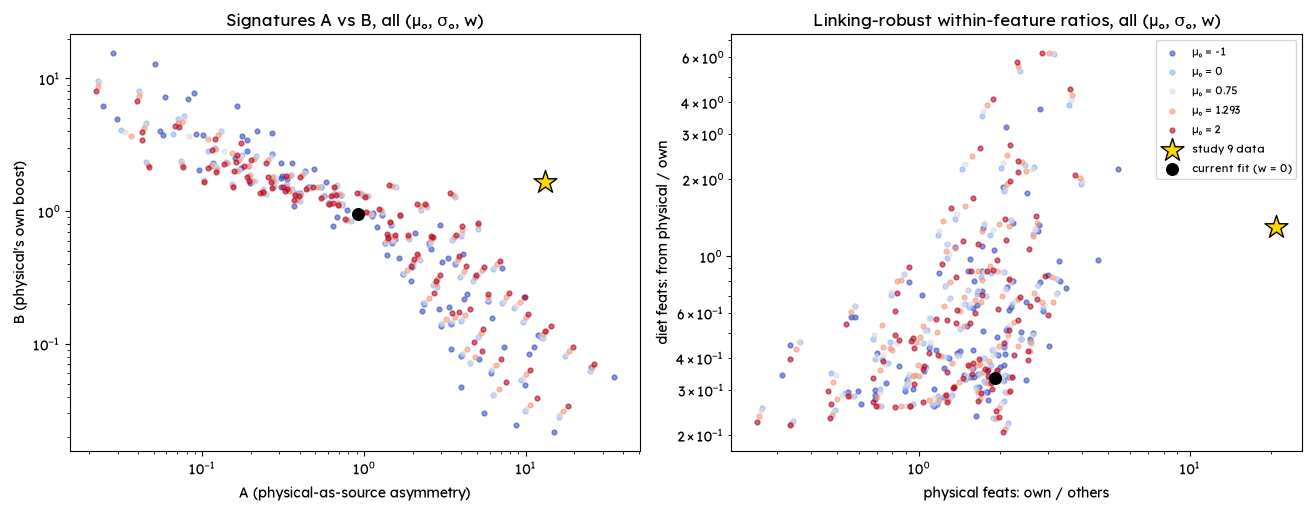

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
cmap = plt.get_cmap('coolwarm')
for ax, (xk, yk, xe, ye, xl, yl) in zip(axes, [
        ('A', 'B', A_emp, B_emp, 'A (physical-as-source asymmetry)', "B (physical's own boost)"),
        ('physical feats: own / others', 'diet feats: from physical / own',
         emp_within['physical feats: own / others'], emp_within['diet feats: from physical / own'],
         'physical feats: own / others', 'diet feats: from physical / own')]):
    for k, mu0 in enumerate(MU0_GRID):
        sub = proxy[proxy.mu0 == mu0]
        ax.scatter(sub[xk].clip(lower=1e-2), sub[yk].clip(lower=1e-2), s=12, alpha=0.6,
                   color=cmap(k / (len(MU0_GRID) - 1)), label=f'μ₀ = {mu0:g}')
    ax.scatter([xe], [ye], marker='*', s=300, c='gold', edgecolors='k', zorder=5, label='study 9 data')
    ax.scatter([ref[xk]], [ref[yk]], marker='o', s=70, c='k', zorder=5, label='current fit (w = 0)')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel(xl); ax.set_ylabel(yl)
axes[0].set_title('Signatures A vs B, all (μ₀, σ₀, w)')
axes[1].set_title('Linking-robust within-feature ratios, all (μ₀, σ₀, w)')
axes[1].legend(fontsize=8, loc='best')
plt.show()

**What this shows:**
- **μ₀ barely matters.** For a given σ₀ and w, the points for different μ₀ sit almost on top of each other. Lowering μ₀ to −1 helps only slightly. A lower μ₀ raises the speaker slopes α roughly equally at every train feature, so it can't make *physical* generics specifically stronger.
- **Nothing reaches the data.**
  - The A–B trade-off curve stays put for every μ₀ and σ₀.
  - The key linking-robust ratio, *physical features own / others*, tops out at about **5 across the whole grid, against about 21 in the data**. The current fit gives 1.9.
- **The closest settings are at the edge of the grid,** w ≈ (1–1.5, 1.5), which is |w| ≈ 1.8–2.1. These imply σ ratios of hundreds to thousands across the space, far outside the N(0, 0.5²) prior. They point up and to the right, which doesn't match either causal hypothesis direction.
- **Correction to section 4:** over the full w grid, the within-feature ratios do vary (diet ratio 0.2–6). But physical own / others never gets near the data.

## Takeaways

1. **The mechanism works in principle.** A non-stationary amplitude does produce asymmetric generalization through the real speaker, in the predicted direction. It's much weaker than the noise-free σ² ratio, because the speaker pins sources in roughly standardized units.
2. **It doesn't produce the study 9 pattern.**
   - The data show physical generics spreading broadly (A ≈ 13) **while** keeping the largest own boost (B ≈ 1.7).
   - At fixed θ, every w falls on a trade-off curve: raising A lowers B. The data point sits far off that curve.
   - The ratios within a feature, which the linking can't distort, barely respond to w. Where they do respond, they move away from the data.
3. **What the data seem to need is a source-side asymmetry.** Physical generics carry more evidence, or spread further, than diet or personality generics. Per-target amplitude can't supply that.
4. **Caveats:**
   - Sections 1–4 held θ (ℓ, μ₀, σ₀, β) at the stationary fit. Section 5 varies μ₀ and σ₀, and the conclusion holds: no setting gets physical features' own / others ratio above about 5 (data: about 21). ℓ and β were not varied.
   - The heterogeneous condition is only a rough baseline. It includes some physical train features.